# 11 · Tools, function calling and structured output with LangChain

A language model only produces text. It cannot look up an order, read a database or do exact arithmetic. **Tool calling** (also called *function calling*) is the convention that lets it ask *you* to do those things:

1. You describe each tool to the model with a name, a description and a **JSON schema** for its arguments.
2. The model answers either with text or with a **tool call**: a structured request `{"name": ..., "args": {...}, "id": ...}`.
3. Your code validates the arguments, runs the function, and sends the result back as a **tool message** that carries the same `id`.
4. The model reads the result and either calls another tool or writes the final answer.

The model never executes anything; your code always does. An **agent** is this exchange in a loop with a goal and some limits. **Structured output** uses the same machinery for a different purpose: instead of calling a function, the model fills in a schema (a Pydantic model) so your program gets typed data instead of prose.

**What you will learn**
- How LangChain turns a Python function into the JSON schema the model sees (`@tool`, type hints, docstrings, Pydantic `args_schema`)
- `bind_tools`, the `AIMessage.tool_calls` the model returns, and `ToolMessage`
- The agent loop by hand (a dozen lines), then the same loop with `langchain.agents.create_agent`
- Error handling: invalid arguments and failing tools are returned to the model so it can correct itself
- Structured output with `with_structured_output`: the three methods, validation, `include_raw`, and retries that feed the error back
- An evaluation on labelled requests: tool-selection accuracy, argument validity, task success, latency and tokens

**Stack:** `langchain-core` (tools, messages), `langchain-ollama` (`ChatOllama` running `qwen2.5:3b` locally), `langchain` (`create_agent`), `pydantic`. If `.env` has a LangSmith key, every call below is traced to the project `llm-edu-suite-11-tools`; without one, nothing changes.

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-11-tools")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : on (project: llm-edu-suite-11-tools)


## 1. Describing tools

The `@tool` decorator reads three things from a function: its **name**, its **docstring** (which becomes the description) and its **type hints** (which become the argument schema). When you need richer constraints, such as per-field descriptions or a regex pattern, give it a Pydantic model as `args_schema`. We define four tools for a small online shop: a weather lookup, a calculator, an orders lookup and a search over the company documentation (a LangChain vector store with `nomic-embed-text` embeddings; notebook 10 covers retrieval in depth).

In [2]:
import os, json
from typing import Literal
from pydantic import BaseModel, Field
from langchain_core.tools import tool

WEATHER_C = {"lima": 19, "cusco": 12, "madrid": 24, "london": 11}          # a fake weather service
ORDERS = {"A100": {"status": "shipped", "total": 120.0},                   # a fake orders database
          "B200": {"status": "processing", "total": 45.5},
          "C300": {"status": "delivered", "total": 80.0}}

@tool
def get_weather(city: str, unit: Literal["C", "F"] = "C") -> dict:
    """Get the current temperature for a city, in Celsius (C) or Fahrenheit (F)."""
    c = WEATHER_C.get(city.strip().lower())
    if c is None:
        return {"error": f"no weather data for {city}"}
    return {"city": city, "temperature": c if unit == "C" else round(c * 9 / 5 + 32), "unit": unit}

class CalculateArgs(BaseModel):
    expression: str = Field(description="An arithmetic expression using only digits, + - * / ** and parentheses, e.g. '(17 * 23) + 4'")

@tool(args_schema=CalculateArgs)
def calculate(expression: str) -> str:
    """Evaluate an arithmetic expression and return the numeric result. Use it for any arithmetic."""
    if not all(ch in "0123456789+-*/(). " for ch in expression):
        raise ValueError(f"unsupported characters in {expression!r}; use only digits, + - * / ** and parentheses")
    return str(round(eval(expression, {"__builtins__": {}}, {}), 4))   # a toy sandbox; never eval untrusted code in production

class OrderArgs(BaseModel):
    order_id: str = Field(pattern=r"^[A-Z]\d{3}$", description="The order id: one capital letter followed by three digits, e.g. A100")

@tool(args_schema=OrderArgs)
def order_status(order_id: str) -> dict:
    """Look up the status and the total amount (in dollars) of a customer order."""
    return ORDERS.get(order_id, {"error": f"order {order_id} not found"})

RETRIEVER = None          # built on first use: a LangChain vector store over data/sample_docs

def _retriever():
    global RETRIEVER
    if RETRIEVER is None:
        from langchain_core.documents import Document
        from langchain_core.vectorstores import InMemoryVectorStore
        folder = os.path.join(ROOT, "data", "sample_docs")
        docs = [Document(open(os.path.join(folder, f), encoding="utf-8").read(), metadata={"source": f}) for f in sorted(os.listdir(folder))]
        RETRIEVER = InMemoryVectorStore.from_documents(docs, get_embeddings()).as_retriever(search_kwargs={"k": 1})
    return RETRIEVER

@tool
def search_docs(query: str) -> str:
    """Search the company documentation: refund policy, shipping times and costs, account security, support hours, API limits."""
    return "\n\n".join(d.page_content for d in _retriever().invoke(query))

TOOLS = [get_weather, calculate, order_status, search_docs]

llm = get_llm()          # ChatOllama(qwen2.5:3b, temperature=0)
print([t.name for t in TOOLS])

['get_weather', 'calculate', 'order_status', 'search_docs']


This is exactly what the model receives for two of the tools: the OpenAI-style function schema that every major provider (and Ollama) accepts. Note where each piece came from: the description is the docstring, `unit` became an `enum` because of the `Literal` hint and is optional because it has a default, and `order_id` carries the description and the regex pattern from the Pydantic field.

In [3]:
from langchain_core.utils.function_calling import convert_to_openai_tool
for t in (get_weather, order_status):
    print(json.dumps(convert_to_openai_tool(t), indent=1))

{
 "type": "function",
 "function": {
  "name": "get_weather",
  "description": "Get the current temperature for a city, in Celsius (C) or Fahrenheit (F).",
  "parameters": {
   "properties": {
    "city": {
     "type": "string"
    },
    "unit": {
     "default": "C",
     "enum": [
      "C",
      "F"
     ],
     "type": "string"
    }
   },
   "required": [
    "city"
   ],
   "type": "object"
  }
 }
}
{
 "type": "function",
 "function": {
  "name": "order_status",
  "description": "Look up the status and the total amount (in dollars) of a customer order.",
  "parameters": {
   "properties": {
    "order_id": {
     "description": "The order id: one capital letter followed by three digits, e.g. A100",
     "pattern": "^[A-Z]\\d{3}$",
     "type": "string"
    }
   },
   "required": [
    "order_id"
   ],
   "type": "object"
  }
 }
}


The description is a prompt. The model chooses tools by reading these few lines, so a vague description ("does stuff with orders") produces wrong calls just as a vague prompt produces wrong answers. Treat tool descriptions as part of your prompt engineering and evaluate changes to them (section 6).

## 2. `bind_tools` and the tool-call message

`llm.bind_tools(TOOLS)` returns a model that sends those schemas with every request. The reply is an `AIMessage`; when the model wants a tool, its `content` is usually empty and `tool_calls` holds the parsed requests. When no tool is useful, the model answers in text and `tool_calls` is empty.

In [4]:
llm_with_tools = llm.bind_tools(TOOLS)
for question in ["What is (17 * 23) + 4?", "What's the weather in Lima, in Fahrenheit?", "Hello! Who wrote Don Quixote?"]:
    t0 = time.time()
    ai = llm_with_tools.invoke(question)
    print(f"Q: {question}  ({time.time() - t0:.1f}s, {ai.usage_metadata['input_tokens']} prompt tokens)")
    print("   content   :", repr(ai.content[:80]))
    print("   tool_calls:", ai.tool_calls)

Q: What is (17 * 23) + 4?  (2.8s, 390 prompt tokens)
   content   : ''
   tool_calls: [{'name': 'calculate', 'args': {'expression': '(17 * 23) + 4'}, 'id': 'f9c1e1e8-edbe-4343-afcd-428b5d7bf784', 'type': 'tool_call'}]


Q: What's the weather in Lima, in Fahrenheit?  (0.8s, 386 prompt tokens)
   content   : ''
   tool_calls: [{'name': 'get_weather', 'args': {'unit': 'F', 'city': 'Lima'}, 'id': '4092be51-575b-45b2-a5e1-6e301c5eafc1', 'type': 'tool_call'}]


Q: Hello! Who wrote Don Quixote?  (1.2s, 385 prompt tokens)
   content   : "I don't have information about who wrote a specific book right now. Could you pl"
   tool_calls: []


The first two questions produced a tool call with well-formed arguments (note `unit: "F"` taken from the enum). The third shows a typical small-model weakness: with tools attached, `qwen2.5:3b` declined to answer a general-knowledge question it could have answered on its own. Tools change the model's behaviour even when they are not called; the evaluation in section 7 measures this.

Look at the prompt-token counts: the tool schemas are sent as part of the prompt on every call, so each tool you add costs tokens on every request whether or not it is used. That is one reason not to give one agent dozens of tools (notebook 14 routes requests to specialists instead).

Under the hood, Ollama's chat template for Qwen2.5 writes the schemas into the system prompt, the model generates a tagged JSON block, and the server parses it back into `tool_calls`. Models are fine-tuned on this format, which is why tool calling works far better with models trained for it than with prompting an arbitrary model to "answer in JSON". You can also force a tool with `bind_tools(TOOLS, tool_choice="calculate")` or force *some* tool with `tool_choice="any"`.

## 3. The loop by hand

To answer, the model needs the tool result. We run the tool and append a `ToolMessage` whose `tool_call_id` matches the call, then call the model again with the whole conversation. Calling `tool.invoke(tool_call)` with the full tool-call dict does the bookkeeping for us: it validates the arguments against the schema, runs the function and returns a `ToolMessage` with the right id.

In [5]:
from langchain_core.messages import HumanMessage, ToolMessage

def run_by_hand(model, tools, question, max_steps=5, verbose=True):
    """The tool-calling loop without any framework: call the model, run the tools it asks for, repeat."""
    by_name = {t.name: t for t in tools}
    bound = model.bind_tools(tools)               # attaches the JSON schemas to every request
    messages = [HumanMessage(question)]
    for step in range(1, max_steps + 1):
        ai = bound.invoke(messages)
        messages.append(ai)
        if not ai.tool_calls:                     # no tool requested: this is the final answer
            break
        for call in ai.tool_calls:
            if call["name"] not in by_name:       # models do invent tool names; tell them instead of crashing
                result = ToolMessage(f"Error: there is no tool named {call['name']!r}", tool_call_id=call["id"], status="error")
            else:
                result = by_name[call["name"]].invoke(call)   # invoking a tool with the whole ToolCall returns a ToolMessage
            messages.append(result)
            if verbose:
                print(f"step {step}: {call['name']}({call['args']}) -> {str(result.content)[:90]}")
    return messages

messages = run_by_hand(llm, TOOLS, "What is the total of order A100 plus 21% tax?")
print("\nfinal answer:", messages[-1].content)
print("message types:", [type(m).__name__ for m in messages])

step 1: order_status({'order_id': 'A100'}) -> {"status": "shipped", "total": 120.0}


step 2: calculate({'expression': '(120.0 * 0.21)'}) -> 25.2



final answer: The tax amount for the order A100 is $25.20. Therefore, the total amount including the 21% tax is $120.00 + $25.20 = $145.20.
message types: ['HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage', 'ToolMessage', 'AIMessage']


That loop is all an agent is. The production versions add the parts we left out: parallel tool execution, error handling, limits on steps and spend, streaming, persistence, human approval, tracing.

## 4. The same loop with `create_agent`

`langchain.agents.create_agent` (LangChain 1.x; it replaces the deprecated `langgraph.prebuilt.create_react_agent`) builds this loop as a LangGraph graph: a `model` node and a `tools` node with an edge back. Its input and output are a dict with the list of `messages`.

In [6]:
from langchain.agents import create_agent

agent = create_agent(llm, TOOLS, system_prompt="You are a helpful assistant for an online shop. Use the tools for facts and arithmetic.")
t0 = time.time()
result = agent.invoke({"messages": [("user", "What's the weather in Madrid, and what is order C300's total minus 15 dollars?")]})
for m in result["messages"]:
    m.pretty_print()
print(f"\n{time.time() - t0:.1f}s")

================================ Human Message =================================

What's the weather in Madrid, and what is order C300's total minus 15 dollars?
================================== Ai Message ==================================
Tool Calls:
  get_weather (242d6d57-4f94-4a9c-ae4f-5ff9fae376d6)
 Call ID: 242d6d57-4f94-4a9c-ae4f-5ff9fae376d6
  Args:
    city: Madrid
    unit: C
  order_status (cc409c23-12cb-4bbd-b8a4-4a9513856e5b)
 Call ID: cc409c23-12cb-4bbd-b8a4-4a9513856e5b
  Args:
    order_id: C300
================================= Tool Message =================================
Name: get_weather

{"city": "Madrid", "temperature": 24, "unit": "C"}
================================= Tool Message =================================
Name: order_status

{"status": "delivered", "total": 80.0}
================================== Ai Message ==================================

The current temperature in Madrid is 24 degrees Celsius. The total amount for order C300, after deducting 15

In [7]:
print(agent.get_graph().draw_mermaid())       # paste into https://mermaid.live to see it; notebook 14 builds graphs like this by hand

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools<hr/><small><em>__tools = get_weather, calculate, order_status, search_docs</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## 5. Errors go back to the model

Two different things can go wrong, and the agent treats them differently.

**Invalid arguments.** The arguments do not match the schema (a missing field, a wrong type, here the `order_id` pattern). The tool node catches the validation error *before* running the function and returns it as a `ToolMessage` with `status="error"`, so the model can read what was wrong and try again. To show it deterministically, we replace the model with a scripted fake (`GenericFakeChatModel` from `langchain_core`, the same one used in the tests) that first sends a bad id and then a corrected one.

In [8]:
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage

class ScriptedModel(GenericFakeChatModel):
    """Replays a fixed list of AIMessages. bind_tools is a no-op because the script already contains the tool calls."""
    def bind_tools(self, tools, **kwargs):
        return self

script = [AIMessage("", tool_calls=[{"name": "order_status", "args": {"order_id": "a-100"}, "id": "call_1"}]),
          AIMessage("", tool_calls=[{"name": "order_status", "args": {"order_id": "A100"}, "id": "call_2"}]),
          AIMessage("Order A100 has shipped.")]
out = create_agent(ScriptedModel(messages=iter(script)), TOOLS).invoke({"messages": [("user", "status of order a-100?")]})
for m in out["messages"]:
    if isinstance(m, ToolMessage):
        print(f"ToolMessage status={m.status}: {m.content}\n")

ToolMessage status=error: Error invoking tool 'order_status' with kwargs {'order_id': 'a-100'} with error:
 order_id: String should match pattern '^[A-Z]\d{3}$'
 Please fix the error and try again.

ToolMessage status=success: {"status": "shipped", "total": 120.0}



**The tool itself fails.** The arguments are valid but the function raises (a timeout, a missing record, here an unsupported operator). By default the exception propagates and the run stops: LangChain does not send arbitrary exception text to the model unless you opt in, because it can leak internal details. You opt in with `ToolErrorMiddleware`, choosing which exceptions become a message and what that message says.

In [9]:
from langchain.agents.middleware import ToolErrorMiddleware

bad = [AIMessage("", tool_calls=[{"name": "calculate", "args": {"expression": "2^10"}, "id": "call_1"}]), AIMessage("done")]
try:
    create_agent(ScriptedModel(messages=iter(bad)), TOOLS).invoke({"messages": [("user", "2^10?")]})
except ValueError as e:
    print("without middleware the run crashes:", e)

def tool_error_to_message(exc, request):
    """Only ValueErrors (bad input) go back to the model; anything else still stops the run."""
    if isinstance(exc, ValueError):
        return f"{request.tool_call['name']} failed: {exc}. Fix the input and try again."
    return None

safe_agent = create_agent(llm, TOOLS, middleware=[ToolErrorMiddleware(tool_error_to_message)])
out = safe_agent.invoke({"messages": [("user", "Use the calculator to compute 2^10, writing the expression exactly as 2^10.")]})
for m in out["messages"][1:]:
    m.pretty_print()

without middleware the run crashes: unsupported characters in '2^10'; use only digits, + - * / ** and parentheses


================================== Ai Message ==================================
Tool Calls:
  calculate (72d64051-9504-4688-833c-9656ccdb69cd)
 Call ID: 72d64051-9504-4688-833c-9656ccdb69cd
  Args:
    expression: 2^10
================================= Tool Message =================================
Name: calculate

calculate failed: unsupported characters in '2^10'; use only digits, + - * / ** and parentheses. Fix the input and try again.
================================== Ai Message ==================================

It seems that the expression '2^10' contains unsupported characters. Please ensure the expression uses only digits, +, -, *, /, **, and parentheses. Let's try again with a valid expression. How about we calculate 2 to the power of 10?
Tool Calls:
  calculate (b9b8e579-4eb9-4ebc-9a32-b1aedf78dfaf)
 Call ID: b9b8e579-4eb9-4ebc-9a32-b1aedf78dfaf
  Args:
    expression: 2**10
================================= Tool Message =================================
Name: calculate

1

Read the transcript above: the error message reached the model and its next turn reacts to it. A 3B model does not always recover the way you would like (it may ask the user instead of retrying with `**`); a precise error message ("use `**` for powers") is what gives it the best chance. Whatever the model does, the run no longer crashes and the failure is visible in the trace.

## 6. Structured output

Often you do not want an action but **data**: the fields of a support ticket, a classification, a plan. `llm.with_structured_output(Schema)` returns a runnable whose output is an instance of your Pydantic model. `ChatOllama` offers three ways to get there:

| method | how it works | guarantees |
|---|---|---|
| `json_schema` (default) | the schema is sent as Ollama's `format`; the server constrains decoding with a grammar so only tokens that keep the JSON valid can be sampled | valid JSON with the right keys and types |
| `function_calling` | the schema is offered as a tool the model must call | as good as the model's tool calling |
| `json_mode` | the server only guarantees *some* valid JSON; the schema has to be described in the prompt | valid JSON, nothing more |

Whatever the method, **Pydantic validates the result on the client**: types, enums (`Literal`), and any custom validators with business rules. Below, the ticket summary must be at most 12 words, a rule the decoder cannot enforce.

In [10]:
from typing import Optional
from pydantic import field_validator

class Ticket(BaseModel):
    """A customer support ticket extracted from an email."""
    customer_name: str
    email: str = Field(description="the customer's email address")
    order_id: Optional[str] = Field(None, description="the order id, like A100, if one is mentioned")
    category: Literal["refund", "shipping", "account", "other"]
    urgency: Literal["low", "medium", "high"]
    summary: str = Field(description="one short sentence, at most 12 words")

    @field_validator("summary")
    @classmethod
    def summary_is_short(cls, v):
        if len(v.split()) > 12:
            raise ValueError(f"summary has {len(v.split())} words but the limit is 12")
        return v

email = ("Hi, this is Maria Lopez (maria.lopez@example.com). My order C300 arrived broken and I want my money back "
         "as soon as possible, it was a birthday present and the party is tomorrow.")
extractor = llm.with_structured_output(Ticket)               # method="json_schema"
ticket = extractor.invoke(email)
print(type(ticket).__name__, ticket.model_dump())

Ticket {'customer_name': 'Maria Lopez', 'email': 'maria.lopez@example.com', 'order_id': None, 'category': 'refund', 'urgency': 'high', 'summary': 'Broken order for a birthday present, urgent refund needed'}


With `include_raw=True` the runnable does not raise when validation fails. It returns a dict with the `raw` `AIMessage`, the `parsed` object (or `None`) and the `parsing_error`, which is what you want in production: log the raw output, then decide what to do. Here we use `json_mode` with a prompt that lists the keys but, as happens in real code, forgets to mention the 12-word rule: the output is valid JSON, but it can still break the business rule.

In [11]:
from pydantic import ValidationError

KEYS_PROMPT = ("Return a JSON object with the keys customer_name, email, order_id, category (refund, shipping, account or other), "
               "urgency (low, medium or high) and summary (a summary of the email).")

def validation_message(parsing_error):
    """The useful part of a parsing error: Pydantic's per-field messages (the parser keeps the ValidationError as __cause__)."""
    cause = parsing_error.__cause__
    if isinstance(cause, ValidationError):
        return "; ".join(f"{'.'.join(map(str, e['loc']))}: {e['msg']}" for e in cause.errors())
    return str(parsing_error)[:300]                     # not even valid JSON

loose = llm.with_structured_output(Ticket, method="json_mode", include_raw=True)
r = loose.invoke([("system", KEYS_PROMPT), ("user", email)])
print("raw output :", r["raw"].content)
print("parsed     :", r["parsed"])
print("error      :", validation_message(r["parsing_error"]) if r["parsing_error"] else None)

raw output : {
  "customer_name": "Maria Lopez",
  "email": "maria.lopez@example.com",
  "order_id": "C300",
  "category": "refund",
  "urgency": "high",
  "summary": "Customer received a broken order (order ID: C300) as a birthday present and urgently needs a refund due to the impending party tomorrow."
}
parsed     : None
error      : summary: Value error, summary has 23 words but the limit is 12


**Retrying.** `runnable.with_retry()` simply repeats the call, and at temperature 0 the same input tends to give the same output, so a blind retry rarely fixes a validation error. What works is to **send the error back**: append the model's bad output and the validation message to the conversation and ask again, the same idea as tool errors in section 5.

In [12]:
def extract_with_feedback(text, system=KEYS_PROMPT, schema=Ticket, method="json_mode", max_attempts=3):
    """Structured output with validation feedback: on failure, show the model its output and the error, and ask again."""
    structured = llm.with_structured_output(schema, method=method, include_raw=True)
    messages = [("system", system), ("user", text)]
    for attempt in range(1, max_attempts + 1):
        r = structured.invoke(messages)
        if r["parsing_error"] is None:
            return r["parsed"], attempt
        error = validation_message(r["parsing_error"])
        print(f"attempt {attempt} failed: {error}")
        messages += [r["raw"], ("user", f"Your JSON failed validation: {error}. Return the corrected JSON object only.")]
    return None, max_attempts

parsed, attempts = extract_with_feedback(email)
print(f"after {attempts} attempt(s):", parsed)

attempt 1 failed: summary: Value error, summary has 23 words but the limit is 12


attempt 2 failed: summary: Value error, summary has 15 words but the limit is 12


after 3 attempt(s): customer_name='Maria Lopez' email='maria.lopez@example.com' order_id='C300' category='refund' urgency='high' summary='Customer received a broken order and urgently requests refund for party.'


Each failed attempt printed the exact validation message, and each retry, having seen it, wrote a shorter summary until one fit the 12-word rule (in our run: 23 words, then 15, then a valid summary on the third attempt). Cap the attempts (here 3) and log how often retries are needed: a rising retry rate is an early sign that a prompt or model change hurt.

### Which method should you use? A small measurement

Eight labelled emails, the three methods, the same `Ticket` schema, and this time the full JSON schema (with the field descriptions) in the system prompt for every method: `json_mode` needs it, and for the other two it keeps the comparison fair. We report the share of outputs that pass validation and, among all eight, the share of correctly extracted fields (name, email, order id, category, urgency; an invalid output counts as all fields wrong).

In [13]:
EMAILS = [
    ("Hi, this is Maria Lopez (maria.lopez@example.com). My order C300 arrived broken and I want my money back as soon as possible, it was a birthday present and the party is tomorrow.",
     {"customer_name": "Maria Lopez", "email": "maria.lopez@example.com", "order_id": "C300", "category": "refund", "urgency": "high"}),
    ("Hello, I can't log into my account since yesterday, it says my password is wrong. Not urgent. - Tom Becker, tom@becker.dev",
     {"customer_name": "Tom Becker", "email": "tom@becker.dev", "order_id": None, "category": "account", "urgency": "low"}),
    ("Where is my parcel? Order A100 was supposed to arrive last week and the tracking hasn't moved. Please check today. Jane Doe <jane.doe@mail.com>",
     {"customer_name": "Jane Doe", "email": "jane.doe@mail.com", "order_id": "A100", "category": "shipping", "urgency": "high"}),
    ("Dear team, could you tell me if you plan to sell gift wrapping? Just curious, no rush. Best, Li Wei (li.wei@example.org)",
     {"customer_name": "Li Wei", "email": "li.wei@example.org", "order_id": None, "category": "other", "urgency": "low"}),
    ("I was charged twice for order B200. I'd like the duplicate payment refunded. Thanks, Omar Haddad, omar.h@example.net",
     {"customer_name": "Omar Haddad", "email": "omar.h@example.net", "order_id": "B200", "category": "refund", "urgency": "medium"}),
    ("Someone changed my account email without my permission!!! Fix this immediately. Anna Schmidt anna.schmidt@example.de",
     {"customer_name": "Anna Schmidt", "email": "anna.schmidt@example.de", "order_id": None, "category": "account", "urgency": "high"}),
    ("Hi, how many days does standard shipping to Canada take for order C300? Thanks, Paul Martin - paul.martin@example.ca",
     {"customer_name": "Paul Martin", "email": "paul.martin@example.ca", "order_id": "C300", "category": "shipping", "urgency": "low"}),
    ("Good morning. I returned the shoes from order A100 two weeks ago and still have no refund. Sofia Rossi (sofia.rossi@example.it)",
     {"customer_name": "Sofia Rossi", "email": "sofia.rossi@example.it", "order_id": "A100", "category": "refund", "urgency": "medium"}),
]
FIELDS = ["customer_name", "email", "order_id", "category", "urgency"]
SCHEMA_PROMPT = ("Extract a support ticket from the email. Reply with a JSON object that follows this JSON schema:\n"
                 + json.dumps(Ticket.model_json_schema()))
so_results, so_misses = {}, {}
for method in ["json_schema", "function_calling", "json_mode"]:
    structured = llm.with_structured_output(Ticket, method=method, include_raw=True)
    valid, correct, seconds = 0, 0, 0.0
    for text, gold in EMAILS:
        t0 = time.time()
        r = structured.invoke([("system", SCHEMA_PROMPT), ("user", text)])
        seconds += time.time() - t0
        if r["parsed"] is not None:
            valid += 1
            correct += sum(getattr(r["parsed"], f) == gold[f] for f in FIELDS)
            so_misses.setdefault(method, []).extend((f, gold[f], getattr(r["parsed"], f)) for f in FIELDS if getattr(r["parsed"], f) != gold[f])
        else:
            so_misses.setdefault(method, []).append(("invalid output", "", validation_message(r["parsing_error"])[:100]))
    so_results[method] = {"valid": valid / len(EMAILS), "field_acc": correct / (len(EMAILS) * len(FIELDS)), "sec": seconds / len(EMAILS)}
    print(f"{method:17s} valid {valid}/{len(EMAILS)}   field accuracy {so_results[method]['field_acc']:.0%}   {so_results[method]['sec']:.2f}s per email")
for method, misses in so_misses.items():
    print(f"\n{method} mistakes (field, expected, got):", misses)

json_schema       valid 8/8   field accuracy 85%   1.72s per email


function_calling  valid 8/8   field accuracy 98%   2.22s per email


json_mode         valid 8/8   field accuracy 98%   1.95s per email

json_schema mistakes (field, expected, got): [('order_id', 'C300', None), ('order_id', 'A100', None), ('order_id', 'B200', None), ('order_id', 'C300', None), ('order_id', 'A100', None), ('urgency', 'medium', 'high')]

function_calling mistakes (field, expected, got): [('urgency', 'low', 'medium')]

json_mode mistakes (field, expected, got): [('urgency', 'medium', 'high')]


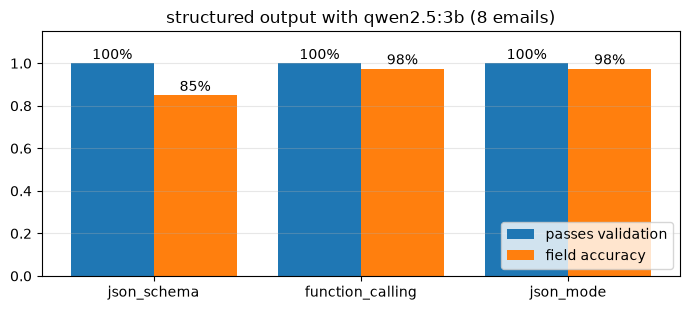

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.2))
methods = list(so_results); xs = np.arange(len(methods))
ax.bar(xs - 0.2, [so_results[m]["valid"] for m in methods], 0.4, label="passes validation")
ax.bar(xs + 0.2, [so_results[m]["field_acc"] for m in methods], 0.4, label="field accuracy")
for x, m in zip(xs, methods):
    ax.text(x - 0.2, so_results[m]["valid"] + 0.02, f"{so_results[m]['valid']:.0%}", ha="center")
    ax.text(x + 0.2, so_results[m]["field_acc"] + 0.02, f"{so_results[m]['field_acc']:.0%}", ha="center")
ax.set_xticks(xs); ax.set_xticklabels(methods); ax.set_ylim(0, 1.15); ax.legend(loc="lower right"); ax.grid(axis="y", alpha=.3)
ax.set_title(f"structured output with qwen2.5:3b ({len(EMAILS)} emails)"); plt.tight_layout(); plt.show()

In our run every method produced a valid `Ticket` for all eight emails (with the full schema in the prompt, the 12-word rule was respected), but they were not equally *correct*. `json_schema` returned `order_id = null` for every email that mentions an order, while `function_calling` and `json_mode` extracted the ids and each missed a single urgency label. Constrained decoding guarantees the **shape** of the output, not its **content**; which method works best depends on the model and the schema, and the only way to know is to measure field by field as above. Urgency is also the most subjective label (is a double charge "medium" or "high"?), so part of that disagreement is label noise.

## 7. Evaluation: does the agent pick the right tool with the right arguments?

Agents are evaluated on the **trajectory**, not just on the final text. For each labelled request we record:

- **tool-selection accuracy**: the set of tools called equals the expected set (including "no tool" for chit-chat);
- **argument validity**: no tool call came back with an error (schema violations count) and the arguments pass a check;
- **task success**: right tools and every expected fact in the final answer;
- **latency** and **tokens** (summed over all model calls in the run, from `usage_metadata`).

Run this after every change to a prompt, a tool description or the model: these numbers move with small wording changes.

In [15]:
from langchain_core.messages import AIMessage, ToolMessage

def trajectory(messages):
    """The tool calls an agent made, the ToolMessages it got back, the token count and the final answer."""
    calls = [tc for m in messages if isinstance(m, AIMessage) for tc in m.tool_calls]
    results = [m for m in messages if isinstance(m, ToolMessage)]
    tokens = sum((m.usage_metadata or {}).get("total_tokens", 0) for m in messages if isinstance(m, AIMessage))
    final = messages[-1].content if isinstance(messages[-1], AIMessage) else ""
    return calls, results, tokens, final

def score_case(messages, expected_tools, facts, arg_check=None):
    """
    tool_ok    : the set of tools called equals the expected set (an empty set means "answer directly").
    args_ok    : no tool call came back as an error and, if given, arg_check(calls) holds.
    success    : every expected fact appears in the final answer (case-insensitive) and the tools were right.
    """
    calls, results, tokens, final = trajectory(messages)
    tool_ok = {c["name"] for c in calls} == set(expected_tools)
    args_ok = all(r.status != "error" for r in results) and (arg_check(calls) if arg_check and calls else True)
    success = tool_ok and all(f.lower() in final.lower() for f in facts)
    return {"tool_ok": tool_ok, "args_ok": args_ok, "success": success, "n_calls": len(calls),
            "n_errors": sum(r.status == "error" for r in results), "tokens": tokens, "answer": final}

city_is = lambda name: (lambda calls: any(c["args"].get("city", "").lower() == name for c in calls))
CASES = [  # (request, expected tools, facts the answer must contain, optional check on the arguments)
    ("What's the weather in Lima right now?", ["get_weather"], ["19"], city_is("lima")),
    ("What is the temperature in Madrid in Fahrenheit?", ["get_weather"], ["75"], lambda calls: any(c["args"].get("unit") == "F" for c in calls)),
    ("What is 17 * 23 + 4?", ["calculate"], ["395"], None),
    ("Compute (120 - 45.5) / 2", ["calculate"], ["37.25"], None),
    ("What is the status of order A100?", ["order_status"], ["shipped"], None),
    ("Has order B200 shipped yet?", ["order_status"], ["processing"], None),
    ("Look up order c300 for me", ["order_status"], ["delivered"], None),
    ("How long does express shipping take?", ["search_docs"], ["1 to 2"], None),
    ("Within how many days can I get a full refund?", ["search_docs"], ["30"], None),
    ("What is the rate limit of the public API?", ["search_docs"], ["100"], None),
    ("Hi! Tell me one fun fact about octopuses.", [], [], None),
    ("Translate 'good morning' into Spanish.", [], ["buenos"], None),
    ("What's the weather in Cusco, and what is 12 * 3?", ["get_weather", "calculate"], ["12", "36"], city_is("cusco")),
    ("What is the total of order C300 plus 15 dollars for express shipping?", ["order_status", "calculate"], ["95"], None),
]
eval_agent = create_agent(llm, TOOLS, system_prompt="You are a helpful assistant for an online shop. Use the tools for facts and arithmetic; answer directly when no tool is needed.",
                          middleware=[ToolErrorMiddleware(tool_error_to_message)])
rows = []
for text, tools_expected, facts, check in CASES:
    t0 = time.time()
    out = eval_agent.invoke({"messages": [("user", text)]}, {"recursion_limit": 12})
    s = score_case(out["messages"], tools_expected, facts, check)
    s["latency"] = time.time() - t0; s["request"] = text
    s["called"] = [c["name"] for c in trajectory(out["messages"])[0]]
    rows.append(s)
    print(f"{'OK ' if s['success'] else 'BAD'} tools={'ok' if s['tool_ok'] else 'WRONG'} args={'ok' if s['args_ok'] else 'ERR'} "
          f"{s['latency']:4.1f}s {s['tokens']:5d} tok  {text[:55]:55s} called={s['called']}")
n = len(rows)
summary = {k: sum(r[k] for r in rows) / n for k in ("tool_ok", "args_ok", "success")}
print(f"\ntool selection {summary['tool_ok']:.0%} | argument validity {summary['args_ok']:.0%} | task success {summary['success']:.0%} "
      f"| median latency {np.median([r['latency'] for r in rows]):.1f}s | mean tokens {np.mean([r['tokens'] for r in rows]):.0f}")

OK  tools=ok args=ok  1.5s   891 tok  What's the weather in Lima right now?                   called=['get_weather']


OK  tools=ok args=ok  1.4s   889 tok  What is the temperature in Madrid in Fahrenheit?        called=['get_weather']


OK  tools=ok args=ok  1.8s   894 tok  What is 17 * 23 + 4?                                    called=['calculate']


OK  tools=ok args=ok  2.1s   915 tok  Compute (120 - 45.5) / 2                                called=['calculate']


OK  tools=ok args=ok  1.7s   901 tok  What is the status of order A100?                       called=['order_status']


OK  tools=ok args=ok  1.8s   900 tok  Has order B200 shipped yet?                             called=['order_status']


... (4 outputs left out)

BAD tools=WRONG args=ok  1.9s   968 tok  Hi! Tell me one fun fact about octopuses.               called=['search_docs']


BAD tools=ok args=ok  0.7s   417 tok  Translate 'good morning' into Spanish.                  called=[]


OK  tools=ok args=ok  1.2s   988 tok  What's the weather in Cusco, and what is 12 * 3?        called=['get_weather', 'calculate']


BAD tools=WRONG args=ERR  1.7s  1015 tok  What is the total of order C300 plus 15 dollars for exp called=['calculate']

tool selection 86% | argument validity 86% | task success 71% | median latency 1.8s | mean tokens 899


In [16]:
for r in rows:
    if not r["success"]:
        print(f"FAILED: {r['request']}\n   called {r['called']}, {r['n_errors']} tool errors\n   answer: {r['answer'][:220]!r}\n")

FAILED: Look up order c300 for me
   called ['order_status'], 1 tool errors
   answer: 'It seems there was an issue with the order ID format. Please ensure the order ID is in the correct format (one capital letter followed by three digits, e.g., A100). Could you please provide the correct order ID?'

FAILED: Hi! Tell me one fun fact about octopuses.
   called ['search_docs'], 0 tool errors
   answer: 'None of the provided information is a fun fact about octopuses. Let me know if you need help finding another piece of information.'

FAILED: Translate 'good morning' into Spanish.
   called [], 0 tool errors
   answer: "No tool is needed for this question. The translation of 'good morning' into Spanish is 'good morning'."

FAILED: What is the total of order C300 plus 15 dollars for express shipping?
   called ['calculate'], 1 tool errors
   answer: "It seems there was an error because the input to the calculate function is not correctly formatted. The function expects a valid arithmetic e

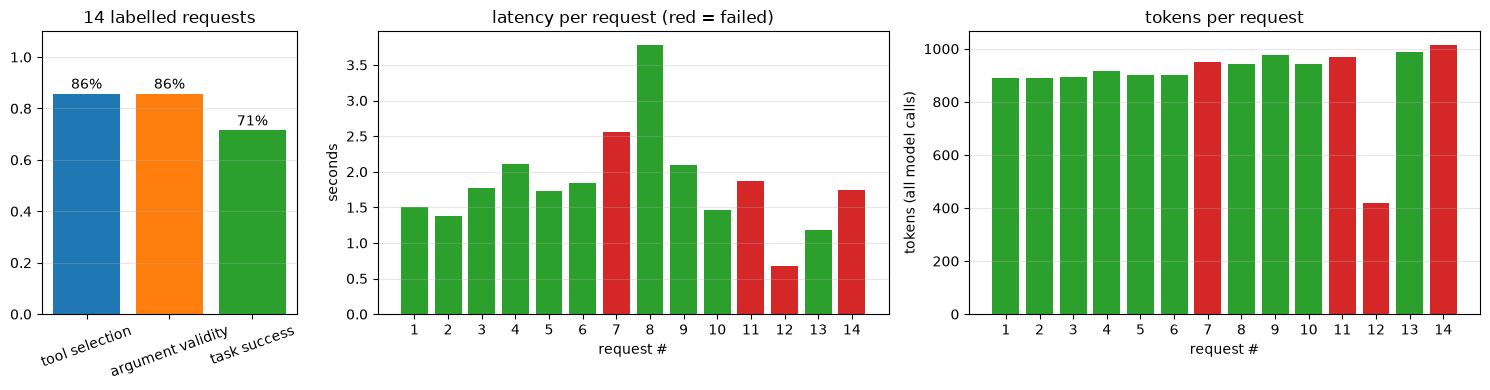

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 2, 2]})
names = ["tool selection", "argument validity", "task success"]
vals = [summary["tool_ok"], summary["args_ok"], summary["success"]]
ax[0].bar(names, vals, color=["tab:blue", "tab:orange", "tab:green"]); ax[0].set_ylim(0, 1.1)
for i, v in enumerate(vals): ax[0].text(i, v + 0.02, f"{v:.0%}", ha="center")
ax[0].tick_params(axis="x", rotation=20); ax[0].set_title(f"{n} labelled requests")
idx = np.arange(n); colors = ["tab:green" if r["success"] else "tab:red" for r in rows]
ax[1].bar(idx, [r["latency"] for r in rows], color=colors); ax[1].set_ylabel("seconds"); ax[1].set_title("latency per request (red = failed)")
ax[2].bar(idx, [r["tokens"] for r in rows], color=colors); ax[2].set_ylabel("tokens (all model calls)"); ax[2].set_title("tokens per request")
for a in ax[1:]:
    a.set_xticks(idx); a.set_xticklabels([str(i + 1) for i in idx]); a.set_xlabel("request #")
for a in ax: a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

**Reading the results.** Single-tool lookups (weather, arithmetic, orders, documentation) were reliable. The failures printed above are instructive:

- **`c300` in lower case** broke the `order_id` pattern. The validation error went back to the model, which asked the user for a correctly formatted id instead of upper-casing it. The schema protected the tool, but the friendlier design is to normalise the id inside the tool and keep strict validation for truly malformed input (notebook 14 does this).
- **The chit-chat request called `search_docs`**: small models over-use tools when tools are available.
- **The translation needed no tool and got none**, but the answer was wrong: a plain model-quality failure that no amount of tool plumbing fixes.
- **The order-plus-shipping request** skipped the order lookup and sent `calculate` an expression it could not evaluate. Multi-step requests are where a 3B model struggles most; notebook 14 measures that directly.

Latency depends heavily on how busy the GPU is (other processes shared it during our run), so compare latencies only within one run. Tokens are dominated by the tool schemas, which are re-sent with every model call (about 390 prompt tokens per call here before any conversation), so a run with two model calls costs roughly twice a run with one.

## Takeaways

- **Tool calling is a protocol, not magic:** schemas go in, `tool_calls` come out, your code runs the function and returns a `ToolMessage` with the matching id. `create_agent` is that loop as a LangGraph graph.
- **Descriptions and schemas are prompts.** Type hints, `Literal` enums, Pydantic field descriptions and patterns both guide the model and validate its output before anything runs.
- **Return errors to the model on purpose:** validation errors come back automatically; execution errors only when you opt in (`ToolErrorMiddleware`), with messages that say how to fix the call.
- **Structured output:** prefer the constrained `json_schema` method when the server supports it, keep business rules in Pydantic validators, use `include_raw=True` in production and retry *with the error*, not blindly.
- **Evaluate trajectories:** tool selection, argument validity, success, latency and tokens on a labelled set, every time a prompt, tool description or model changes. Production practice: sandbox code execution, log every trajectory (LangSmith), cap steps and spend, and treat tool output as untrusted data (notebook 13 covers prompt injection).

**Next:** `12_recommender_systems.ipynb`. The agents track continues in `14_agentic_ai.ipynb` (LangGraph graphs: guardrails, human approval, memory, planning, reflection, multi-agent routing) and `16_mcp_model_context_protocol.ipynb` (the standard way to expose tools to any agent).